# Sequential-Based Recommendation Models

Pada sistem rekomendasi modern, urutan interaksi pengguna seperti *clicks*, *views*, dan *purchases* dapat digunakan untuk mempelajari perubahan preferensi pengguna dari waktu ke waktu. Model klasik seperti *Collaborative Filtering* dan *Matrix Factorization* memodelkan interaksi pengguna–item tanpa mempertimbangkan urutan temporal. Model rekomendasi sekuensial memperluas pendekatan ini dengan mempelajari pola dan dependensi antaritem berdasarkan riwayat interaksi pengguna.

Notebook ini membahas model rekomendasi berbasis sekuensial. **Self-Attentive Sequential Recommendation (SASRec)** menggabungkan mekanisme *Causal Self-Attention* untuk menangkap dependensi antaritem dalam urutan interaksi pengguna dengan *Point-Wise Feed-Forward Network* (FFN) untuk mempelajari representasi nonlinier dari fitur laten.

Model ini diimplementasikan menggunakan PyTorch dan dilatih pada MovieLens untuk memprediksi item berikutnya berdasarkan urutan kronologis interaksi pengguna.

In [1]:
from copy import deepcopy
from pathlib import Path
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from typing import Any
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [2]:
def plotTrainingAndValidationLoss(
  modelData: dict[str, Any],
  modelName: str,
):
  # Menentukan nomor epoch berdasarkan jumlah riwayat training loss.
  epochNumbers = range(1, len(modelData['trainLossHistory']) + 1)

  # Membuat figure dan axes untuk visualisasi loss.
  fig, ax = plt.subplots(figsize=(10, 5))

  # Menampilkan perubahan training loss pada setiap epoch.
  sns.lineplot(
    x=epochNumbers,
    y=modelData['trainLossHistory'],
    marker='o',
    markevery=(49, 50),
    label='Training Loss',
    ax=ax,
  )

  # Menampilkan perubahan validation loss pada setiap epoch.
  sns.lineplot(
    x=epochNumbers,
    y=modelData['valLossHistory'],
    marker='o',
    markevery=(49, 50),
    label='Validation Loss',
    ax=ax,
  )

  # Menandai epoch terbaik dengan garis vertikal putus-putus.
  ax.axvline(
    x=modelData['bestEpoch'],
    color='gray',
    linestyle='--',
    label=f'Best Epoch: {modelData['bestEpoch']}',
  )

  # Menandai titik validation loss terendah pada epoch terbaik.
  ax.scatter(
    modelData['bestEpoch'],
    modelData['bestValLoss'],
    color='red',
    s=80,
    zorder=5,
  )

  # Mengatur judul grafik dan label masing-masing sumbu.
  ax.set(
    title=f'{modelName} Training and Validation Loss',
    xlabel='Epoch',
    ylabel='Loss',
  )

  # Menampilkan legenda dan menyesuaikan tata letak grafik.
  ax.legend()
  plt.grid()
  plt.tight_layout()
  plt.show()
  

In [3]:
# Menentukan direktori utama dan lokasi file dataset MovieLens 100K.
pathMl = Path('../res/data/movielens')
pathZip = pathMl / 'ml-100k.zip'
pathRatings = pathMl / 'ml-100k' / 'u.data'
pathItem = pathMl / 'ml-100k' / 'u.item'

# Membuat direktori penyimpanan jika belum tersedia.
pathMl.mkdir(parents=True, exist_ok=True)

# Mengunduh dataset MovieLens 100K jika file ZIP belum tersedia.
if not pathZip.exists():
  urlretrieve(
    'https://files.grouplens.org/datasets/movielens/ml-100k.zip',
    pathZip,
  )

# Mengekstrak file rating pengguna jika belum tersedia.
if not pathRatings.exists():
  with ZipFile(pathZip) as archive:
    archive.extract('ml-100k/u.data', path=pathMl)
    

In [4]:
# Membaca dataset rating pengguna dan film dari MovieLens 100K.
df = pd.read_csv(
  pathRatings, 
  sep='\t', 
  header=None,
  usecols=[0, 1, 2, 3],
  names=['userId', 'movieId', 'rating', 'timestamp'],
)

# Mengonversi ID pengguna dan film menjadi indeks numerik mulai dari 0.
df.userId = df.userId.astype('category').cat.codes
df.movieId = df.movieId.astype('category').cat.codes

# Menghitung jumlah pengguna dan film unik untuk menentukan ukuran tabel embedding.
numUsers = df.userId.nunique()
numItems = df.movieId.nunique()

# Menampilkan informasi struktur, tipe data, dan jumlah nilai non-null pada dataset.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   userId     100000 non-null  int16
 1   movieId    100000 non-null  int16
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int16(2), int64(2)
memory usage: 1.9 MB


## Self-Attentive Sequential Recommendation (SASRec)

**Self-Attentive Sequential Recommendation (SASRec)** adalah model rekomendasi sekuensial yang menggunakan **Self-Attention** dan **Point-Wise Feed-Forward Network (FFN)** untuk mempelajari pola interaksi pengguna secara berurutan. Self-Attention mempelajari relevansi antar item dalam riwayat interaksi, sedangkan FFN mempelajari hubungan nonlinier antarfitur laten. Kedua komponen menghasilkan representasi kontekstual yang digunakan untuk memprediksi item berikutnya.

Pada implementasi `class SAS(nn.Module)`, kelas `SASDataset` membentuk sekuens input, target positif, dan target negatif berdasarkan riwayat interaksi pengguna. Metode `forward()` menggabungkan **Item Embedding** dan **Positional Embedding**, kemudian memprosesnya melalui beberapa blok `SASBlock`. Fungsi `trainSAS()` menghitung skor prediksi melalui perkalian titik (*dot product*) antara representasi kontekstual dan embedding item, kemudian menggunakan `nn.BCEWithLogitsLoss()` selama pelatihan. Saat inferensi, representasi pada posisi terakhir digunakan untuk menghitung skor dan mengurutkan kandidat item.

> **Catatan:** Penggunaan **GPU direkomendasikan** untuk mempercepat proses pelatihan SASRec, khususnya ketika panjang sekuens, dimensi embedding, jumlah blok Self-Attention, atau jumlah data meningkat. Pelatihan tetap dapat dilakukan menggunakan **CPU**, tetapi biasanya membutuhkan waktu lebih lama. Jika komputer tidak memiliki GPU yang kompatibel, alternatifnya adalah menjalankan notebook melalui **Google Colab** atau **Kaggle Notebooks** dengan akselerator GPU, sesuai ketersediaan dan batas penggunaan masing-masing layanan.

---

## 1. Persamaan Model & Pemetaan Variabel Kode

Model SASRec menggabungkan embedding item, embedding posisi, Causal Self-Attention, dan FFN menggunakan persamaan berikut.

$$
\begin{aligned}
\widehat{\mathbf E}_t
&=\operatorname{Dropout}(\mathbf M_{s_t}+\mathbf P_{n-m+t})\\
\mathbf F^{(0)}&=\widehat{\mathbf E}\\
\mathbf X^{(\ell)}
&=\operatorname{LayerNorm}_1^{(\ell)}(\mathbf F^{(\ell-1)})\\
\mathbf Q^{(\ell)}&=\mathbf X^{(\ell)}\mathbf W^{Q,(\ell)}\\
\mathbf K^{(\ell)}&=\mathbf X^{(\ell)}\mathbf W^{K,(\ell)}\\
\mathbf V^{(\ell)}&=\mathbf X^{(\ell)}\mathbf W^{V,(\ell)}\\
\mathbf Z^{(\ell)}
&=\frac{\mathbf Q^{(\ell)}(\mathbf K^{(\ell)})^\top}{\sqrt d}\\
\widehat{\mathbf Z}^{(\ell)}&=\mathbf Z^{(\ell)}+\mathbf C\\
\mathbf A^{(\ell)}&=\operatorname{softmax}(\widehat{\mathbf Z}^{(\ell)})\\
\mathbf{SA}^{(\ell)}
&=\operatorname{Dropout}(\mathbf A^{(\ell)}\mathbf V^{(\ell)})\\
\mathbf H^{(\ell)}&=\mathbf F^{(\ell-1)}+\mathbf{SA}^{(\ell)}\\
\mathbf F^{(\ell)}
&=\mathbf H^{(\ell)}
+\operatorname{Dropout}\left(
\operatorname{FFN}^{(\ell)}(
\operatorname{LayerNorm}_2^{(\ell)}(\mathbf H^{(\ell)}))
\right)\\
r_{i,t}&=\mathbf F_t^{(b)}\mathbf M_i^\top\\
\hat y_{i,t}&=\sigma(r_{i,t})=\frac{1}{1+e^{-r_{i,t}}}.
\end{aligned}
$$

Indeks item dimulai dari 0 agar sesuai dengan pengindeksan PyTorch, sedangkan posisi sekuens pada persamaan dimulai dari 1. Setiap persamaan di atas berlaku untuk satu sekuens interaksi pengguna. Kode menghitung seluruh sekuens dalam satu *batch* sekaligus.

Matriks bobot pada persamaan menggunakan konvensi perkalian vektor baris. PyTorch `nn.Linear` menyimpan bobot dalam orientasi transpose dari konvensi tersebut.

### Notasi Umum: Pengguna, Item, dan Sekuens Interaksi

Untuk pengguna $u$, riwayat interaksi diurutkan secara kronologis berdasarkan timestamp. Dua interaksi terakhir dipisahkan sebagai target validasi dan pengujian.

$$
\begin{aligned}
\mathcal S^u&=(S_1^u,S_2^u,\ldots,S_L^u),\\
\mathcal S_{\mathrm{train}}^u
&=(S_1^u,S_2^u,\ldots,S_{L-2}^u),\\
L_{\mathrm{train}}&=L-2.
\end{aligned}
$$

Pada kelas `SASDataset`, input dan target pelatihan dibentuk dengan mengambil interaksi terakhir dari riwayat pelatihan.

$$
\begin{aligned}
s_t&=S_{L_{\mathrm{train}}-n+t-1}^u,\\
o_t&=S_{L_{\mathrm{train}}-n+t}^u,
\qquad 1\leq t\leq n.
\end{aligned}
$$

Untuk validasi, input menggunakan $n$ interaksi terakhir dari riwayat pelatihan, sedangkan target positif menggunakan interaksi kedua terakhir dari riwayat lengkap pengguna.

$$
\begin{aligned}
s_t^{\mathrm{val}}&=S_{L_{\mathrm{train}}-n+t}^u,\\
o^{\mathrm{val}}&=S_{L-1}^u.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $u,\ i$ | `userId`, `movieId` | Indeks pengguna dan film setelah pengodean. Keduanya dimulai dari 0. |
| $\mathcal I$ | `items`, `I` | Kumpulan seluruh indeks item dalam dataset. |
| $\lvert\mathcal I\rvert$ | `self.numOfItems`, `numItems` | Jumlah item unik yang menentukan ukuran tabel item embedding. |
| $\mathcal S^u$ | `history` | Riwayat lengkap interaksi pengguna yang telah diurutkan secara kronologis. |
| $S_j^u$ | `history[j - 1]` | Item pada posisi ke-$j$ dalam riwayat interaksi pengguna. |
| $L$ | `history.numel()` | Jumlah seluruh interaksi pengguna. |
| $\mathcal S_{\mathrm{train}}^u$ | `Su = history[:-2]` | Riwayat pelatihan setelah mengeluarkan target validasi dan pengujian. |
| $L_{\mathrm{train}}$ | `Su.numel()` | Jumlah interaksi yang tersedia untuk pelatihan. |
| $n$ | `self.maxSeqLength` | Panjang maksimum sekuens interaksi. |
| $m$ | `s.size(1)` pada `SAS.forward()` | Panjang aktual sekuens setelah pemotongan, dengan $m\leq n$. |
| $B$ | `batchSize`, `s.size(0)` | Jumlah sekuens dalam satu batch. |
| $t,\ s_t$ | Indeks posisi, `s[:, t - 1]` | Posisi dan indeks item pada sekuens input. |
| $o_t$ | `o[:, t - 1]` saat pelatihan | Target positif berupa item berikutnya pada setiap posisi sekuens. |
| $o^{\mathrm{val}}$ | `o = history[-2]` pada `SASDataset` | Target positif validasi berupa satu item yang disisihkan dari pelatihan. |

Misalnya, dengan riwayat interaksi $(A,B,C,D,E,F,G)$ dan `maxSeqLength=3`, riwayat pelatihan menjadi $(A,B,C,D,E)$. Input pelatihan adalah $(B,C,D)$ dengan target positif $(C,D,E)$, sedangkan input validasi adalah $(C,D,E)$ dengan target positif $F$. Item $G$ disisihkan sebagai target pengujian.

### Notasi Item Embedding dan Positional Embedding

SASRec menggunakan item embedding untuk merepresentasikan karakteristik laten setiap item dan positional embedding untuk merepresentasikan urutan interaksi. Kedua embedding dijumlahkan, kemudian diproses menggunakan dropout.

$$
\begin{aligned}
\widehat{\mathbf E}_t
&=\operatorname{Dropout}(\mathbf M_{s_t}+\mathbf P_{n-m+t}),\\
\mathbf F^{(0)}&=\widehat{\mathbf E}.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $d$ | `self.embedDim` | Jumlah koordinat laten untuk setiap item dan posisi sekuens. |
| $\mathbf M$ | `self.embedItems.weight` | Matriks item embedding berukuran $(\lvert\mathcal I\rvert,d)$. |
| $\mathbf M_{s_t}$ | `self.embedItems(s)` | Vektor embedding dari item pada posisi $t$ dalam sekuens input. |
| $\mathbf M_i$ | `self.embedItems.weight[i]` | Vektor embedding kandidat item $i$ yang juga digunakan untuk menghitung skor prediksi. |
| $\mathbf P$ | `self.embedLPos.weight` | Matriks positional embedding berukuran $(n,d)$. |
| $\mathbf P_{n-m+t}$ | `self.embedLPos(positions)` | Vektor embedding posisi yang sesuai dengan letak item dalam sekuens. |
| $n-m+t-1$ | Elemen `positions` | Indeks posisi berbasis 0 yang digunakan untuk mengambil positional embedding. |
| $\operatorname{Dropout}$ | `self.dropout(...)` | Menonaktifkan elemen secara acak selama pelatihan untuk mengurangi overfitting. |
| $\widehat{\mathbf E}$ | `E_hat` | Hasil penjumlahan item embedding dan positional embedding setelah dropout. |
| $\mathbf F^{(0)}$ | `F = E_hat` | Representasi awal yang digunakan sebagai input blok Self-Attention pertama. |

Dengan `maxSeqLength=16` dan `embedDim=32`, satu sekuens sepanjang 16 item menghasilkan representasi berukuran $(16,32)$. Apabila panjang input kurang dari 16, positional embedding diambil dari posisi terakhir tabel embedding agar posisi item terbaru tetap berada pada indeks terakhir.

### Notasi Layer Normalization

Layer Normalization menormalisasi fitur laten pada setiap posisi sekuens secara independen sebelum Self-Attention dan FFN.

$$
\begin{aligned}
\mu_t&=\frac{1}{d}\sum_{f=1}^{d}x_{tf},\\
\sigma_t^2&=\frac{1}{d}\sum_{f=1}^{d}(x_{tf}-\mu_t)^2,\\
\operatorname{LayerNorm}(\mathbf x_t)
&=\boldsymbol\gamma\odot
\frac{\mathbf x_t-\mu_t}{\sqrt{\sigma_t^2+\epsilon}}
+\boldsymbol\beta.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\mathbf x_t$ | `x[:, t - 1, :]` | Vektor representasi input pada posisi $t$. |
| $x_{tf}$ | Satu elemen `x` | Nilai koordinat laten ke-$f$ pada posisi $t$. |
| $f$ | Indeks dimensi embedding | Posisi koordinat laten dalam satu vektor representasi. |
| $\mu_t$ | Dihitung oleh `nn.LayerNorm` | Rata-rata seluruh koordinat laten pada posisi $t$. |
| $\sigma_t^2$ | Dihitung oleh `nn.LayerNorm` | Varians seluruh koordinat laten pada posisi $t$. |
| $\epsilon$ | `eps=1e-7` | Konstanta kecil untuk mencegah pembagian dengan nol. |
| $\boldsymbol\gamma$ | `self.norm1.weight`, `self.norm2.weight` | Parameter skala yang dipelajari selama pelatihan. |
| $\boldsymbol\beta$ | `self.norm1.bias`, `self.norm2.bias` | Parameter bias yang dipelajari selama pelatihan. |
| $\odot$ | Perkalian elemen | Perkalian setiap koordinat hasil normalisasi dengan parameter skala. |
| $\operatorname{LayerNorm}$ | `self.norm1(...)`, `self.norm2(...)` | Operasi normalisasi pada dimensi embedding. |

Layer Normalization mempertahankan ukuran representasi $(m,d)$ untuk setiap sekuens. Setiap blok `SASBlock` memiliki dua Layer Normalization dengan parameter yang dipelajari secara independen.

### Notasi Causal Self-Attention

Self-Attention mempelajari relevansi antaritem dengan membentuk representasi Query, Key, dan Value. Causal mask membatasi setiap posisi agar hanya dapat mengakses item pada posisi saat ini dan sebelumnya.

$$
\begin{aligned}
\mathbf X&=\operatorname{LayerNorm}_1(\mathbf x),\\
\mathbf Q&=\mathbf X\mathbf W^Q,\\
\mathbf K&=\mathbf X\mathbf W^K,\\
\mathbf V&=\mathbf X\mathbf W^V,\\
\mathbf Z&=\frac{\mathbf Q\mathbf K^\top}{\sqrt d}.
\end{aligned}
$$

Causal mask diberikan oleh

$$
C_{tj}=
\begin{cases}
0,&j\leq t,\\
-\infty,&j>t.
\end{cases}
$$

Skor attention yang telah diberikan mask dinormalisasi menggunakan softmax, kemudian digunakan untuk mengagregasi representasi Value.

$$
\begin{aligned}
\widehat{\mathbf Z}&=\mathbf Z+\mathbf C,\\
A_{tj}&=\frac{\exp(\widehat Z_{tj})}
{\sum_{k=1}^{m}\exp(\widehat Z_{tk})},\\
\mathbf{SA}&=\operatorname{Dropout}(\mathbf A\mathbf V),\\
\mathbf H&=\mathbf x+\mathbf{SA}.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\mathbf x$ | `x` pada `SASBlock.forward()` | Representasi input yang berasal dari embedding awal atau blok sebelumnya. |
| $\mathbf X$ | `X = self.norm1(x)` | Representasi input setelah Layer Normalization. |
| $\mathbf W^Q$ | `self.Wq.weight` | Bobot proyeksi Query berukuran $(d,d)$, dengan orientasi transpose terhadap persamaan. |
| $\mathbf W^K$ | `self.Wk.weight` | Bobot proyeksi Key berukuran $(d,d)$, dengan orientasi transpose terhadap persamaan. |
| $\mathbf W^V$ | `self.Wv.weight` | Bobot proyeksi Value berukuran $(d,d)$, dengan orientasi transpose terhadap persamaan. |
| $\mathbf Q$ | `Q = self.Wq(X)` | Representasi Query yang digunakan untuk menentukan informasi yang relevan. |
| $\mathbf K$ | `K = self.Wk(X)` | Representasi Key yang dibandingkan dengan Query untuk menghitung relevansi antarposisi. |
| $\mathbf V$ | `V = self.Wv(X)` | Representasi Value yang diagregasi berdasarkan bobot attention. |
| $\mathbf K^\top$ | `K.transpose(-2, -1)` | Transpose matriks Key yang memungkinkan perkalian matriks dengan Query. |
| $\sqrt d$ | `self.embedDim**0.5` | Faktor skala untuk mengendalikan besarnya skor dot product. |
| $\mathbf Z$ | `Z` | Matriks skor attention berukuran $(m,m)$ untuk setiap sekuens. |
| $t,\ j,\ k$ | Indeks posisi sekuens | Posisi Query, posisi Key, dan indeks penjumlahan pada softmax. |
| $\mathbf C$ | `C` | Matriks causal mask yang mencegah akses terhadap item pada posisi berikutnya. |
| $\widehat{\mathbf Z}$ | `Z_hat = Z + C` | Matriks skor attention setelah penerapan causal mask. |
| $A_{tj}$ | Satu elemen `A` | Bobot attention dari posisi Query $t$ terhadap posisi Key $j$. |
| $\mathbf A$ | `A = torch.softmax(Z_hat, dim=-1)` | Matriks bobot attention yang dinormalisasi pada setiap baris. |
| $\mathbf{SA}$ | `SA = self.dropout(A @ V)` | Representasi hasil agregasi Value berdasarkan bobot attention setelah dropout. |
| $\mathbf H$ | `H = x + SA` | Representasi hasil Residual Connection antara input awal dan output Self-Attention. |

Saat posisi $t$ memprediksi item berikutnya, causal mask memastikan bahwa model hanya menggunakan informasi dari posisi 1 sampai $t$. Dengan demikian, item pada posisi berikutnya tidak dapat diakses melalui Self-Attention.

### Notasi Point-Wise Feed-Forward Network (FFN)

FFN memproses representasi setiap posisi secara independen melalui dua layer linear dan fungsi aktivasi ReLU. Sebelum memasuki FFN, representasi hasil Self-Attention dinormalisasi kembali.

$$
\begin{aligned}
\mathbf U&=\operatorname{LayerNorm}_2(\mathbf H),\\
\operatorname{FFN}(\mathbf U)
&=\operatorname{ReLU}
\left(\mathbf U\mathbf W^{(1)}+\mathbf b^{(1)}\right)
\mathbf W^{(2)}+\mathbf b^{(2)},\\
\mathbf O_{\mathrm{FFN}}
&=\operatorname{Dropout}(\operatorname{FFN}(\mathbf U)),\\
\mathbf F&=\mathbf H+\mathbf O_{\mathrm{FFN}}.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\mathbf H$ | `H` | Representasi hasil Self-Attention dan Residual Connection. |
| $\mathbf U$ | `self.norm2(H)` | Representasi yang telah dinormalisasi sebelum memasuki FFN. |
| $\mathbf W^{(1)},\ \mathbf b^{(1)}$ | `self.ffn[0].weight`, `self.ffn[0].bias` | Bobot dan bias pada layer linear pertama. |
| $\operatorname{ReLU}$ | `self.ffn[1]` | Fungsi aktivasi $\max(0,z)$ untuk setiap elemen $z$. |
| $\mathbf W^{(2)},\ \mathbf b^{(2)}$ | `self.ffn[2].weight`, `self.ffn[2].bias` | Bobot dan bias pada layer linear kedua. |
| $\operatorname{FFN}$ | `self.ffn(...)` | Jaringan yang mempelajari hubungan nonlinier antarfitur laten pada setiap posisi. |
| $\mathbf O_{\mathrm{FFN}}$ | `ffnOutput` | Hasil FFN setelah penerapan dropout. |
| $\mathbf F$ | `F = H + ffnOutput` | Output akhir blok Self-Attention setelah Residual Connection. |

Dengan `embedDim=32`, FFN menggunakan urutan dimensi $32\rightarrow32\rightarrow32$. Dimensi output dipertahankan agar dapat dijumlahkan dengan representasi $\mathbf H$ melalui Residual Connection.

### Notasi Self-Attention Blocks

SASRec dapat menggunakan beberapa blok Self-Attention secara bertingkat. Output setiap blok menjadi input bagi blok berikutnya.

$$
\begin{aligned}
\mathbf F^{(0)}&=\widehat{\mathbf E},\\
\mathbf F^{(\ell)}
&=\operatorname{SASBlock}^{(\ell)}
(\mathbf F^{(\ell-1)}),
\qquad 1\leq\ell\leq b.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\ell$ | Posisi `block` dalam `self.blocks` | Nomor blok Self-Attention yang sedang diproses. |
| $b$ | `self.numOfAttentionBlocks` | Jumlah seluruh blok Self-Attention. |
| $\mathbf F^{(0)}$ | `F = E_hat` | Representasi awal sebelum memasuki blok pertama. |
| $\mathbf F^{(\ell-1)}$ | `F` sebelum `block(F)` | Representasi hasil blok sebelumnya. |
| $\operatorname{SASBlock}^{(\ell)}$ | `self.blocks[ell - 1]` | Blok Self-Attention dengan parameter yang dipelajari secara independen. |
| $\mathbf F^{(\ell)}$ | `F = block(F)` | Representasi kontekstual hasil blok ke-$\ell$. |
| $\mathbf F^{(b)}$ | `F` pada `return F` | Representasi kontekstual dari blok Self-Attention terakhir. |

Dengan `numOfAttentionBlocks=2`, model memproses representasi melalui urutan $\mathbf F^{(0)}\rightarrow\mathbf F^{(1)}\rightarrow\mathbf F^{(2)}$. Setiap blok mempertahankan ukuran representasi $(m,d)$ untuk setiap sekuens.

### Notasi Self-Attentive Sequential Recommendation (SASRec)

Skor prediksi dihitung melalui perkalian titik antara representasi kontekstual pada posisi $t$ dan embedding kandidat item $i$.

$$
r_{i,t}=\mathbf F_t^{(b)}\mathbf M_i^\top,
\qquad
\hat y_{i,t}=\sigma(r_{i,t}).
$$

Untuk pelatihan, model menghitung skor item positif dan negatif pada setiap posisi sekuens.

$$
\begin{aligned}
r_t^+&=\mathbf F_t^{(b)}\mathbf M_{o_t}^\top,\\
r_t^-&=\mathbf F_t^{(b)}\mathbf M_{j_t}^\top.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\mathbf F_t^{(b)}$ | `F[:, t - 1, :]` | Representasi kontekstual pada posisi $t$ dari blok Self-Attention terakhir. |
| $\mathbf M_i^\top$ | Transpose vektor `model.embedItems.weight[i]` | Representasi embedding kandidat item yang digunakan dalam perkalian titik. |
| $o_t$ | `o[:, t - 1]` | Indeks item positif pada posisi $t$ selama pelatihan. |
| $j_t$ | `j[:, t - 1]` | Indeks item negatif hasil negative sampling pada posisi $t$. |
| $\mathbf M_{o_t}$ | `model.embedItems(o)` | Embedding item positif yang digunakan untuk menghitung skor positif. |
| $\mathbf M_{j_t}$ | `model.embedItems(j)` | Embedding item negatif yang digunakan untuk menghitung skor negatif. |
| $r_t^+$ | `(F * model.embedItems(o)).sum(dim=-1)` | Skor mentah item positif pada setiap posisi prediksi. |
| $r_t^-$ | `(F * model.embedItems(j)).sum(dim=-1)` | Skor mentah item negatif pada setiap posisi prediksi. |
| $r_{i,t}$ | Skor dot product kandidat item | Skor relevansi kandidat item $i$ berdasarkan representasi pada posisi $t$. |
| $\sigma$ | `torch.sigmoid(...)` | Fungsi yang mengubah logit menjadi skor antara 0 dan 1. |
| $\hat y_{i,t}$ | Hasil sigmoid dari logit | Skor prediksi biner item berdasarkan konteks interaksi pengguna. |

Dengan `maxSeqLength=16`, `embedDim=32`, dan `numOfAttentionBlocks=2`, model menghasilkan **16 representasi kontekstual**, masing-masing dengan **32 fitur laten**. Selama pelatihan, setiap representasi digunakan untuk menghitung satu skor positif dan satu skor negatif. Saat validasi dan inferensi, hanya representasi pada posisi terakhir yang digunakan.

Metode `forward()` mengembalikan representasi kontekstual, bukan skor prediksi. Perhitungan skor positif dan negatif dilakukan secara terpisah pada fungsi `trainSAS()`.

---

## 2. Cara Kerja Metode `forward(self, x)`

Sebelum `forward()` dipanggil, `SASDataset` membentuk tensor indeks item bertipe `torch.long`. Pada implementasi ini, setiap sampel memiliki panjang sekuens yang sama tanpa padding. `DataLoader` menggabungkan sampel menjadi tensor berukuran `(batchSize, seqLength)`.

Alur komputasi di dalam `SAS.forward(x)` mengikuti urutan berikut.

1. **`s`** mengambil maksimal `self.maxSeqLength` item terakhir dari setiap sekuens menggunakan `x[:, -self.maxSeqLength:]`.
2. **`positions`** membentuk indeks posisi menggunakan `torch.arange()` untuk mengambil positional embedding yang sesuai dengan panjang aktual sekuens.
3. **`E_hat`** menjumlahkan hasil `self.embedItems(s)` dan `self.embedLPos(positions)`, kemudian menerapkan dropout. Hasilnya berukuran `(batchSize, seqLength, embedDim)`.
4. **`F`** menerima representasi awal `E_hat` tanpa menerapkan dropout kembali.
5. **`self.blocks`** memproses representasi `F` melalui seluruh blok `SASBlock` secara berurutan.
6. **`return F`** mengembalikan representasi kontekstual dari blok Self-Attention terakhir dengan ukuran `(batchSize, seqLength, embedDim)`.

Setiap blok `SASBlock.forward(x)` melakukan komputasi berikut.

1. **`X`** menormalisasi representasi input melalui `self.norm1(x)` pada dimensi embedding.
2. **`Q`, `K`, dan `V`** memproyeksikan `X` melalui tiga layer linear tanpa bias. Ketiganya berukuran `(batchSize, seqLength, embedDim)`.
3. **`Z`** menghitung skor attention menggunakan `Q @ K.transpose(-2, -1) / self.embedDim**0.5`. Hasilnya berukuran `(batchSize, seqLength, seqLength)`.
4. **`C` dan `Z_hat`** membentuk causal mask berukuran `(seqLength, seqLength)` dengan nilai $-\infty$ di atas diagonal utama, kemudian menambahkannya pada `Z`.
5. **`A`** menerapkan `torch.softmax(Z_hat, dim=-1)` sehingga setiap baris matriks attention memiliki jumlah bobot sebesar 1.
6. **`SA` dan `H`** menghitung agregasi Value melalui `A @ V`, menerapkan dropout, kemudian menambahkan hasilnya pada input awal melalui Residual Connection.
7. **`ffnOutput`** memproses `H` melalui `self.norm2`, `self.ffn`, dan dropout untuk mempelajari hubungan nonlinier antarfitur laten.
8. **`F`** menjumlahkan `H` dan `ffnOutput` untuk menghasilkan representasi kontekstual akhir dari satu blok Self-Attention.

Konfigurasi `embedDim=32`, `maxSeqLength=16`, dan `numOfAttentionBlocks=2` menghasilkan representasi berukuran $(B,16,32)$ pada setiap blok apabila input memiliki panjang 16. Meskipun representasi setiap item dapat berubah melalui Self-Attention dan FFN, jumlah posisi dan dimensi embedding tetap dipertahankan.

---

## 3. Proses Pelatihan dengan Adam, Binary Cross-Entropy, dan Early Stopping

Fungsi `trainSAS(model, trainLoader, valLoader)` melatih model dengan **Adam**, learning rate awal `lr=1e-3`, parameter `betas=(0.9, 0.98)`, dan maksimum `epochs=20`. Item embedding digunakan bersama oleh input model dan perhitungan skor prediksi sehingga gradien dari kedua jalur berkontribusi pada pembaruan `model.embedItems.weight`.

### Pembentukan Target Positif dan Negatif

Selama pelatihan, `SASDataset` membentuk target positif dari item berikutnya pada setiap posisi sekuens. Target negatif diambil secara acak dari kumpulan item yang tidak terdapat dalam riwayat pelatihan pengguna.

$$
\begin{aligned}
\mathcal N_{\mathrm{train}}^u
&=\mathcal I\setminus
\operatorname{set}(\mathcal S_{\mathrm{train}}^u),\\
j_t&\sim\operatorname{Uniform}(\mathcal N_{\mathrm{train}}^u).
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\mathcal N_{\mathrm{train}}^u$ | `Nu` pada mode pelatihan | Kumpulan kandidat item negatif yang tidak terdapat dalam riwayat pelatihan pengguna. |
| $\mathcal I$ | `items` | Kumpulan seluruh indeks item. |
| $\mathcal S_{\mathrm{train}}^u$ | `Su` | Riwayat interaksi pengguna yang digunakan untuk pelatihan. |
| $\setminus$ | `torch.isin(..., invert=True)` | Operasi untuk memilih item yang tidak terdapat dalam riwayat interaksi. |
| $j_t$ | Elemen `j` | Item negatif yang diambil untuk posisi prediksi $t$. |
| $\operatorname{Uniform}$ | `torch.randint(...)` | Distribusi pengambilan sampel dengan peluang yang sama untuk setiap kandidat negatif. |

* **Target Positif ($y^+=1$)** diberikan pada item berikutnya yang benar-benar terdapat dalam riwayat interaksi pengguna.
* **Target Negatif ($y^-=0$)** diberikan pada item hasil negative sampling yang tidak terdapat dalam riwayat pelatihan pengguna.
* **Dynamic Negative Sampling** dilakukan pada `SASDataset.__getitem__()` sehingga target negatif dapat berubah setiap kali sampel pelatihan diakses.

Pada implementasi ini, seluruh rating MovieLens 100K diperlakukan sebagai interaksi implisit tanpa membedakan nilai rating 1–5. Item yang tidak terdapat dalam riwayat pelatihan diperlakukan sebagai kandidat negatif, tetapi tidak berarti bahwa pengguna pasti tidak menyukai item tersebut.

### Tujuan Pelatihan (Fungsi *Loss*)

Untuk posisi prediksi $t$, skor item positif $r_t^+$ dan skor item negatif $r_t^-$ menghasilkan loss berikut.

$$
\ell_t=
-\left[
\log\sigma(r_t^+)
+\log(1-\sigma(r_t^-))
\right].
$$

Untuk satu *batch* berisi $B$ sekuens dengan panjang $n$, jumlah posisi prediksi tanpa padding adalah $N=Bn$. Kode menghitung rata-rata loss positif dan negatif secara terpisah, kemudian menjumlahkannya.

$$
\mathcal L_{\mathrm{BCE}}
=-\frac{1}{N}
\sum_{q=1}^{B}\sum_{t=1}^{n}
\left[
\log\sigma(r_{q,t}^+)
+\log(1-\sigma(r_{q,t}^-))
\right].
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $q$ | Indeks sampel dalam batch | Posisi sekuens pengguna dalam satu batch. |
| $B$ | `B = s.size(0)` | Jumlah sekuens dalam batch. |
| $N$ | `N = o.numel()` | Jumlah posisi prediksi yang valid dalam batch tanpa padding. |
| $r_{q,t}^+$ | `r[:B]` | Logit item positif pada setiap posisi sekuens. |
| $r_{q,t}^-$ | `r[B:]` | Logit item negatif pada setiap posisi sekuens. |
| $y^+$ | `torch.ones_like(r[:B])` | Target biner bernilai 1 untuk seluruh item positif. |
| $y^-$ | `torch.zeros_like(r[B:])` | Target biner bernilai 0 untuk seluruh item negatif. |
| $\ell_t$ | Loss positif dan negatif pada satu posisi | Jumlah BCE item positif dan item negatif pada posisi $t$. |
| $\mathcal L_{\mathrm{BCE}}$ | `loss` sebelum regularisasi | Jumlah rata-rata BCE positif dan rata-rata BCE negatif. |

* **`BCEWithLogitsLoss`** menghitung sigmoid dan BCE secara numerik stabil langsung dari logit.
* **`criterion(r[:B], torch.ones_like(r[:B]))`** menghitung rata-rata loss item positif.
* **`criterion(r[B:], torch.zeros_like(r[B:]))`** menghitung rata-rata loss item negatif.

Penjumlahan kedua rata-rata tersebut menghasilkan loss yang dinormalisasi berdasarkan jumlah posisi prediksi $N$, bukan jumlah seluruh prediksi biner $2N$.

### Regularisasi L2

Untuk mengurangi risiko overfitting, fungsi `trainSAS()` menyediakan regularisasi L2 pada item embedding dan positional embedding.

$$
\begin{aligned}
\mathcal L_{\mathrm{reg}}
&=\frac{\lambda}{2}
\left(
\|\mathbf M\|_F^2+
\|\mathbf P\|_F^2
\right),\\
\mathcal L_{\mathrm{train}}
&=\mathcal L_{\mathrm{BCE}}+\mathcal L_{\mathrm{reg}}.
\end{aligned}
$$

| Simbol Matematis | Variabel dalam Kode | Penjelasan |
| :--- | :--- | :--- |
| $\lambda$ | `reg` | Koefisien yang menentukan kekuatan regularisasi L2. |
| $\mathbf M$ | `model.embedItems.weight` | Matriks embedding seluruh item. |
| $\mathbf P$ | `model.embedLPos.weight` | Matriks embedding seluruh posisi. |
| $\|\mathbf M\|_F^2$ | `model.embedItems.weight.square().sum()` | Jumlah kuadrat seluruh elemen item embedding. |
| $\|\mathbf P\|_F^2$ | `model.embedLPos.weight.square().sum()` | Jumlah kuadrat seluruh elemen positional embedding. |
| $\mathcal L_{\mathrm{reg}}$ | `lossReg` | Penalti regularisasi L2 yang ditambahkan selama pelatihan. |
| $\mathcal L_{\mathrm{train}}$ | `loss` | Total loss yang digunakan untuk menghitung gradien. |

Dengan `reg=0.0`, regularisasi L2 tidak diterapkan sehingga total training loss hanya terdiri dari BCE. Apabila `reg > 0`, regularisasi ditambahkan pada training loss, tetapi tidak pada validation loss.

### Langkah Pembaruan Parameter (Per Satu Batch)

1. **`model.train(training)`** mengaktifkan mode pelatihan ketika fungsi `iterateDataLoader()` menerima `training=True`.
2. **`s`, `o`, dan `j`** dipindahkan ke `device` untuk menyediakan sekuens input, target positif, dan target negatif.
3. **`optimizer.zero_grad()`** mengosongkan gradien sebelum menghitung gradien untuk batch saat ini.
4. **`F` dan `r`** dihitung melalui `model(s)` dan perkalian titik antara representasi kontekstual dengan embedding item positif dan negatif. Kedua kelompok logit digabungkan menggunakan `torch.cat(..., dim=0)`.
5. **`B`, `N`, dan `loss`** menentukan jumlah sekuens, jumlah posisi prediksi, dan total BCE positif serta negatif. Jika `reg > 0`, regularisasi L2 ditambahkan pada `loss`.
6. **`loss.backward()`** menghitung gradien terhadap item embedding, positional embedding, parameter Self-Attention, Layer Normalization, dan FFN.
7. **`optimizer.step()`** memperbarui parameter model menggunakan Adam.
8. **`totalLoss` dan `totalValidPositions`** mengakumulasi `loss.item() * N` dan jumlah posisi prediksi $N$. Setelah seluruh batch selesai, `totalLoss` dibagi dengan `totalValidPositions` dan dikembalikan sebagai rata-rata training loss. Hasilnya disimpan dalam `trainLossHistory`.

Dengan cara ini, batch terakhir yang lebih kecil mendapat bobot sesuai jumlah posisi prediksinya. Penggunaan `torch.set_grad_enabled(training)` memastikan bahwa perhitungan gradien hanya diaktifkan selama pelatihan.

### Validasi dan Early Stopping

Setelah setiap epoch, `iterateDataLoader(valLoader, False)` mengaktifkan mode evaluasi melalui `model.train(False)` dan menonaktifkan perhitungan gradien melalui `torch.set_grad_enabled(False)`.

Berbeda dengan pelatihan yang menghitung skor pada seluruh posisi sekuens, validasi menggunakan `F[:, -1, :]` untuk mengambil representasi pada posisi terakhir. Target positif merupakan interaksi kedua terakhir dari riwayat lengkap pengguna, sedangkan target negatif ditentukan sekali saat inisialisasi dataset validasi.

Pada implementasi `SASDataset`, kandidat negatif validasi mengecualikan riwayat pelatihan dan target positif validasi, tetapi tidak mengecualikan target pengujian.

$$
\mathcal N_{\mathrm{val}}^u
=\mathcal I\setminus
\operatorname{set}(S_1^u,\ldots,S_{L-1}^u).
$$

Skor prediksi validasi dihitung menggunakan persamaan berikut.

$$
\begin{aligned}
r_q^+&=\mathbf F_{q,n}^{(b)}\mathbf M_{o_q}^\top,\\
r_q^-&=\mathbf F_{q,n}^{(b)}\mathbf M_{j_q}^\top,\\
\mathcal L_{\mathrm{val}}
&=-\frac{1}{B}\sum_{q=1}^{B}
\left[
\log\sigma(r_q^+)
+\log(1-\sigma(r_q^-))
\right].
\end{aligned}
$$

Rata-rata loss seluruh sampel validasi disimpan dalam `valLossHistory`. Target negatif validasi yang tetap membantu menjaga konsistensi pengukuran validation loss antar-epoch.

Jika `valLoss < bestValLoss`, fungsi menyimpan nomor epoch berbasis 1 pada `bestEpoch`, menyalin parameter dengan `deepcopy(model.state_dict())`, dan mengatur `patienceCounter` ke 0. Jika validation loss tetap atau meningkat, penghitung bertambah satu. Dengan `patience=3`, pelatihan berhenti setelah **3 epoch berturut-turut** tanpa perbaikan.

Di akhir pelatihan, `model.load_state_dict(bestModelState)` memulihkan parameter dari epoch terbaik. Fungsi mengembalikan kamus berisi `bestEpoch`, `bestValLoss`, `trainLossHistory`, dan `valLossHistory`. Kamus tersebut dapat digunakan oleh `plotTrainingAndValidationLoss()` untuk menampilkan perubahan training loss, validation loss, dan epoch terbaik.

---

## 4. Contoh Hitungan Sederhana

Misalkan model mempelajari riwayat interaksi seorang pengguna untuk memprediksi film berikutnya. Untuk mempermudah perhitungan, digunakan 4 film, `maxSeqLength=2`, `embedDim=2`, satu blok Self-Attention (`numOfAttentionBlocks=1`), dan `dropout=0.0`. Parameter berikut dipilih untuk ilustrasi.

* **Kumpulan item:** $\mathcal I=\{A,B,C,D\}$ dengan indeks masing-masing $0,1,2,3$.
* **Riwayat pelatihan pengguna:** $\mathcal S_{\mathrm{train}}^u=(A,B,C)$.
* **Item embedding:** $\mathbf M_A=[0.8,0.1]$, $\mathbf M_B=[0.1,0.8]$, $\mathbf M_C=[0.2,0.8]$, dan $\mathbf M_D=[0.8,0.2]$.
* **Positional embedding:** $\mathbf P_1=[0.2,-0.1]$ dan $\mathbf P_2=[-0.1,0.2]$.
* **Parameter Self-Attention:** $\mathbf W^Q=\mathbf W^K=\mathbf W^V=\mathbf I_2$, dengan $\mathbf I_2$ sebagai matriks identitas berukuran $(2,2)$.
* **Parameter Layer Normalization:** $\boldsymbol\gamma=[1,1]$ dan $\boldsymbol\beta=[0,0]$ pada kedua Layer Normalization. Nilai $\epsilon$ sangat kecil sehingga hasil normalisasi dibulatkan untuk mempermudah perhitungan.
* **Parameter FFN:** $\mathbf W^{(1)}=\mathbf I_2$, $\mathbf W^{(2)}=0.5\mathbf I_2$, dan $\mathbf b^{(1)}=\mathbf b^{(2)}=[0,0]$.
* **Regularisasi L2:** $\lambda=0$ sehingga loss hanya berasal dari BCE.

Contoh ini menggunakan riwayat pelatihan yang sudah dipisahkan dari target validasi dan pengujian. Perhitungan ditampilkan untuk satu sekuens dengan dimensi batch dihilangkan.

**Langkah Perhitungan:**

1. **`s`, `o`, dan `j` (Input dan Target).** Ambil dua interaksi sebelum item terakhir sebagai input, kemudian geser satu posisi untuk membentuk target positif.

   $$
   s=(A,B),\qquad o=(B,C).
   $$

   Kandidat negatif diperoleh dari item yang tidak terdapat dalam riwayat pelatihan.

   $$
   \begin{aligned}
   \mathcal N_{\mathrm{train}}^u
   &=\{A,B,C,D\}\setminus\{A,B,C\}\\
   &=\{D\},\\
   j&=(D,D).
   \end{aligned}
   $$

2. **`E_hat` dan `F` (Item Embedding dan Positional Embedding).** Jumlahkan embedding setiap item dengan embedding posisi yang sesuai. Dropout tidak mengubah nilai karena `dropout=0.0`.

   $$
   \begin{aligned}
   \widehat{\mathbf E}_1
   &=[0.8,0.1]+[0.2,-0.1]=[1,0],\\
   \widehat{\mathbf E}_2
   &=[0.1,0.8]+[-0.1,0.2]=[0,1].
   \end{aligned}
   $$

   $$
   \mathbf F^{(0)}=\widehat{\mathbf E}
   =\begin{bmatrix}
   1&0\\
   0&1
   \end{bmatrix}.
   $$

3. **`X`, `Q`, `K`, dan `V` (Layer Normalization dan Projection).** Normalisasi setiap posisi sekuens. Untuk posisi pertama, rata-rata dan variansnya adalah

   $$
   \mu_1=\frac{1+0}{2}=0.5,\qquad
   \sigma_1^2=\frac{(1-0.5)^2+(0-0.5)^2}{2}=0.25.
   $$

   Hasil Layer Normalization adalah

   $$
   \mathbf X\approx
   \begin{bmatrix}
   1&-1\\
   -1&1
   \end{bmatrix}.
   $$

   Karena seluruh matriks proyeksi merupakan matriks identitas, diperoleh

   $$
   \mathbf Q=\mathbf K=\mathbf V\approx
   \begin{bmatrix}
   1&-1\\
   -1&1
   \end{bmatrix}.
   $$

4. **`Z`, `C`, dan `Z_hat` (Scaled Dot-Product Attention dan Causal Mask).** Hitung perkalian Query dan transpose Key, kemudian bagi dengan $\sqrt d$.

   $$
   \begin{aligned}
   \mathbf Z
   &=\frac{1}{\sqrt2}
   \begin{bmatrix}
   1&-1\\
   -1&1
   \end{bmatrix}
   \begin{bmatrix}
   1&-1\\
   -1&1
   \end{bmatrix}\\
   &\approx
   \begin{bmatrix}
   1.4142&-1.4142\\
   -1.4142&1.4142
   \end{bmatrix}.
   \end{aligned}
   $$

   Terapkan causal mask agar posisi pertama tidak dapat mengakses posisi kedua.

   $$
   \mathbf C=
   \begin{bmatrix}
   0&-\infty\\
   0&0
   \end{bmatrix}.
   $$

   $$
   \widehat{\mathbf Z}
   =\mathbf Z+\mathbf C
   \approx
   \begin{bmatrix}
   1.4142&-\infty\\
   -1.4142&1.4142
   \end{bmatrix}.
   $$

5. **`A`, `SA`, dan `H` (Attention Weight dan Residual Connection).** Terapkan softmax pada setiap baris matriks skor attention.

   $$
   \begin{aligned}
   A_{11}
   &=\frac{e^{1.4142}}{e^{1.4142}+e^{-\infty}}=1,\\
   A_{12}&=0,\\
   A_{21}
   &=\frac{e^{-1.4142}}{e^{-1.4142}+e^{1.4142}}
   \approx0.0558,\\
   A_{22}
   &=\frac{e^{1.4142}}{e^{-1.4142}+e^{1.4142}}
   \approx0.9442.
   \end{aligned}
   $$

   $$
   \mathbf A\approx
   \begin{bmatrix}
   1&0\\
   0.0558&0.9442
   \end{bmatrix}.
   $$

   Hitung agregasi Value berdasarkan bobot attention.

   $$
   \begin{aligned}
   \mathbf{SA}
   &=\mathbf A\mathbf V\\
   &\approx
   \begin{bmatrix}
   1&0\\
   0.0558&0.9442
   \end{bmatrix}
   \begin{bmatrix}
   1&-1\\
   -1&1
   \end{bmatrix}\\
   &=
   \begin{bmatrix}
   1&-1\\
   -0.8884&0.8884
   \end{bmatrix}.
   \end{aligned}
   $$

   Tambahkan hasil Self-Attention pada representasi awal.

   $$
   \mathbf H=\mathbf F^{(0)}+\mathbf{SA}
   \approx
   \begin{bmatrix}
   2&-1\\
   -0.8884&1.8884
   \end{bmatrix}.
   $$

6. **`ffnOutput` dan `F` (Feed-Forward Network dan Output Blok).** Normalisasi kembali representasi $\mathbf H$, kemudian proses melalui layer linear pertama, ReLU, dan layer linear kedua.

   $$
   \mathbf U=\operatorname{LayerNorm}_2(\mathbf H)
   \approx
   \begin{bmatrix}
   1&-1\\
   -1&1
   \end{bmatrix}.
   $$

   $$
   \begin{aligned}
   \mathbf O_{\mathrm{FFN}}
   &=\operatorname{ReLU}
   (\mathbf U\mathbf W^{(1)}+\mathbf b^{(1)})
   \mathbf W^{(2)}+\mathbf b^{(2)}\\
   &\approx
   \begin{bmatrix}
   1&0\\
   0&1
   \end{bmatrix}
   \begin{bmatrix}
   0.5&0\\
   0&0.5
   \end{bmatrix}\\
   &=
   \begin{bmatrix}
   0.5&0\\
   0&0.5
   \end{bmatrix}.
   \end{aligned}
   $$

   Tambahkan hasil FFN melalui Residual Connection.

   $$
   \begin{aligned}
   \mathbf F^{(1)}
   &=\mathbf H+\mathbf O_{\mathrm{FFN}}\\
   &\approx
   \begin{bmatrix}
   2&-1\\
   -0.8884&1.8884
   \end{bmatrix}
   +
   \begin{bmatrix}
   0.5&0\\
   0&0.5
   \end{bmatrix}\\
   &=
   \begin{bmatrix}
   2.5&-1\\
   -0.8884&2.3884
   \end{bmatrix}.
   \end{aligned}
   $$

7. **`r` (Skor Prediksi Positif dan Negatif).** Hitung perkalian titik antara representasi kontekstual dan embedding target pada setiap posisi.

   Untuk posisi pertama, target positif adalah film $B$ dan target negatif adalah film $D$.

   $$
   \begin{aligned}
   r_1^+
   &=\mathbf F_1^{(1)}\mathbf M_B^\top\\
   &=(2.5\times0.1)+(-1\times0.8)=-0.55,\\
   r_1^-
   &=\mathbf F_1^{(1)}\mathbf M_D^\top\\
   &=(2.5\times0.8)+(-1\times0.2)=1.8.
   \end{aligned}
   $$

   Untuk posisi kedua, target positif adalah film $C$ dan target negatif adalah film $D$.

   $$
   \begin{aligned}
   r_2^+
   &=\mathbf F_2^{(1)}\mathbf M_C^\top\\
   &=(-0.8884\times0.2)+(2.3884\times0.8)\\
   &=1.73304,\\
   r_2^-
   &=\mathbf F_2^{(1)}\mathbf M_D^\top\\
   &=(-0.8884\times0.8)+(2.3884\times0.2)\\
   &=-0.23304.
   \end{aligned}
   $$

   Penggabungan skor positif dan negatif melalui `torch.cat(..., dim=0)` menghasilkan

   $$
   \mathbf r\approx
   \begin{bmatrix}
   -0.55&1.73304\\
   1.8&-0.23304
   \end{bmatrix}.
   $$

8. **`sigmoid` dan `loss` (Skor Prediksi dan BCE).** Untuk setiap posisi, sigmoid menghasilkan skor prediksi item positif dan negatif.

   $$
   \begin{aligned}
   \hat y_1^+&=\sigma(-0.55)\approx0.3659,\\
   \hat y_1^-&=\sigma(1.8)\approx0.8581,\\
   \hat y_2^+&=\sigma(1.73304)\approx0.8498,\\
   \hat y_2^-&=\sigma(-0.23304)\approx0.4420.
   \end{aligned}
   $$

   Hitung jumlah BCE positif dan negatif pada setiap posisi menggunakan nilai sebelum pembulatan.

   $$
   \begin{aligned}
   \ell_1
   &=-\log(\sigma(-0.55))
   -\log(1-\sigma(1.8))\\
   &\approx1.0055+1.9530=2.9585,\\
   \ell_2
   &=-\log(\sigma(1.73304))
   -\log(1-\sigma(-0.23304))\\
   &\approx0.1628+0.5834=0.7462.
   \end{aligned}
   $$

   Karena terdapat dua posisi prediksi yang valid, rata-rata loss adalah

   $$
   \mathcal L_{\mathrm{BCE}}
   =\frac{\ell_1+\ell_2}{2}
   \approx\mathbf{1.8523}.
   $$

   Dengan $\lambda=0$, total training loss adalah

   $$
   \mathcal L_{\mathrm{train}}
   =\mathcal L_{\mathrm{BCE}}
   \approx\mathbf{1.8523}.
   $$

Pada posisi pertama, skor item negatif lebih tinggi daripada skor item positif sehingga menghasilkan loss yang lebih besar. Pada posisi kedua, skor film $C$ sebesar $1.73304$ lebih tinggi daripada skor film $D$ sebesar $-0.23304$, sehingga model berhasil menempatkan film $C$ di atas film $D$.

Selama pelatihan, `loss.backward()` menghitung gradien dari seluruh posisi prediksi dan `optimizer.step()` memperbarui parameter model untuk meminimalkan loss tersebut. Nilai pada contoh berasal dari parameter ilustratif, bukan hasil pelatihan pada dataset MovieLens 100K.

---

## 5. Aplikasi Self-Attentive Sequential Recommendation (SASRec)

1. **Rekomendasi Film.** Memprediksi film berikutnya yang kemungkinan akan dipilih pengguna berdasarkan urutan film yang sebelumnya telah ditonton atau diberi rating.
2. **Rekomendasi Produk E-Commerce.** Mempelajari pola interaksi pengguna terhadap produk, seperti urutan klik atau pembelian, untuk merekomendasikan produk berikutnya.
3. **Rekomendasi Konten Digital.** Mempelajari perubahan preferensi pengguna berdasarkan urutan konsumsi musik, video, atau artikel untuk memberikan rekomendasi yang relevan dengan interaksi terbaru.
4. **Pemeringkatan Kandidat Item.** Menggunakan representasi kontekstual pada posisi terakhir untuk menghitung skor kandidat item melalui perkalian titik dengan item embedding, kemudian mengurutkan kandidat dari skor tertinggi. Sigmoid mempertahankan urutan tersebut.

Pada implementasi ini, `SASDataset` membentuk sekuens dari **ID film yang diurutkan berdasarkan timestamp**. Timestamp digunakan untuk menentukan urutan interaksi, bukan sebagai fitur input model. Untuk menggunakan informasi seperti genre, nilai rating, atau interval waktu antarinteraksi, diperlukan fitur tambahan dan penyesuaian arsitektur model.

---

## 6. Kelebihan dan Kekurangan Self-Attentive Sequential Recommendation (SASRec)

| Kelebihan (*Pros*) | Kekurangan (*Cons*) |
| :--- | :--- |
| **Mempelajari Pola Interaksi Sekuensial.** SASRec mempertimbangkan urutan interaksi sehingga dapat menangkap perubahan preferensi pengguna yang tidak diperhatikan oleh model rekomendasi nonsekuensial. | **Kompleksitas Self-Attention Kuadratik.** Self-Attention standar membutuhkan komputasi $O(n^2d)$ dan penyimpanan matriks attention berukuran $O(n^2)$ per sekuens, sehingga biaya komputasi meningkat ketika panjang sekuens bertambah. |
| **Menangkap Dependensi Jangka Pendek dan Panjang.** Mekanisme Self-Attention dapat menghubungkan suatu posisi dengan interaksi sebelumnya tanpa harus memproses seluruh posisi secara rekursif seperti RNN. | **Bergantung pada Kualitas Riwayat Interaksi.** Riwayat yang sangat pendek, tidak lengkap, atau tidak mencerminkan preferensi pengguna dapat membatasi kualitas representasi yang dipelajari. |
| **Mempertimbangkan Relevansi Antaritem Secara Adaptif.** Bobot attention memungkinkan model memberikan kontribusi yang berbeda pada setiap interaksi sesuai konteks sekuens pengguna. | **Membutuhkan Tuning Hiperparameter.** Panjang sekuens, dimensi embedding, jumlah blok Self-Attention, dropout, dan learning rate memengaruhi kualitas rekomendasi dan biaya komputasi. |
| **Mendukung Komputasi Paralel.** Representasi seluruh posisi sekuens dapat dihitung secara paralel selama pelatihan dengan tetap mempertahankan batasan kausal melalui attention mask. | **Rentan Overfitting.** Tabel embedding dan beberapa blok Self-Attention dapat memiliki banyak parameter dibandingkan jumlah interaksi yang tersedia, khususnya pada dataset yang relatif kecil. |
| **Mempelajari Representasi Pengguna yang Dinamis.** Representasi preferensi dibentuk dari riwayat interaksi sehingga dapat berubah ketika pengguna melakukan interaksi baru tanpa memerlukan embedding pengguna yang eksplisit. | **Menghadapi Masalah Cold-Start.** Pengguna tanpa riwayat interaksi yang memadai sulit direpresentasikan, sedangkan item baru belum memiliki embedding yang dipelajari dari data pelatihan. |
| **Menggunakan Item Embedding Bersama.** Representasi item dapat dipelajari melalui perannya sebagai input sekuens dan sebagai kandidat prediksi tanpa memerlukan dua tabel embedding item yang terpisah. | **Sensitif terhadap Strategi Negative Sampling.** Item yang belum diinteraksikan belum tentu tidak disukai pengguna. Pemilihan sampel negatif dapat memengaruhi kualitas pembelajaran dan hasil pemeringkatan. |

In [5]:
class SASBlock(nn.Module):
  """
    Implementasi blok Self-Attention pada model SASRec menggunakan PyTorch.
    Menggabungkan Causal Self-Attention dan Point-Wise Feed-Forward Network (FFN)
    dengan Layer Normalization, Dropout, dan Residual Connection.

    Persamaan Model:

    Layer Normalization:
    X = LayerNorm(x)

    Self-Attention:
    Q = X * W^Q
    K = X * W^K
    V = X * W^V

    Z = (Q * K^T) / sqrt(d)
    Z_hat = Z + C
    A = softmax(Z_hat)
    SA = Dropout(A * V)

    Residual Connection:
    H = x + SA

    Point-Wise Feed-Forward Network:
    FFN(x) = ReLU(x * W^(1) + b^(1)) * W^(2) + b^(2)

    Output:
    F = H + Dropout(FFN(LayerNorm(H)))
  """
  
  def __init__(
    self,
    embedDim: int,
    dropout=0.2,
  ):
    """
      Inisialisasi arsitektur dan parameter blok Self-Attention.

      Args:
        embedDim (int): Merepresentasikan simbol d, yaitu dimensi embedding setiap item.
        dropout (float, optional): Probabilitas menonaktifkan elemen secara acak
          selama pelatihan untuk mengurangi overfitting. Default 0.2.
    """
    
    super().__init__()
    
    # d: Dimensi embedding dan representasi laten setiap item.
    self.embedDim = embedDim
    
    # Dropout: Menonaktifkan elemen secara acak selama pelatihan.
    self.dropout = nn.Dropout(dropout)
    
    # 1. LAYER NORMALIZATION

    # Normalisasi input sebelum Self-Attention.
    self.norm1 = nn.LayerNorm(embedDim, eps=1e-7)
    
    # Normalisasi input sebelum Feed-Forward Network.
    self.norm2 = nn.LayerNorm(embedDim, eps=1e-7)
    
    # 2. QUERY, KEY, DAN VALUE PROJECTION

    # W^Q: Matriks bobot query berukuran (d, d).
    # Digunakan untuk membentuk representasi pencarian informasi setiap item.
    self.Wq = nn.Linear(embedDim, embedDim, bias=False)
    
    # W^K: Matriks bobot key berukuran (d, d).
    # Digunakan untuk menentukan relevansi setiap item terhadap query.
    self.Wk = nn.Linear(embedDim, embedDim, bias=False)
    
    # W^V: Matriks bobot value berukuran (d, d).
    # Digunakan untuk membentuk informasi yang akan diagregasi oleh Self-Attention.
    self.Wv = nn.Linear(embedDim, embedDim, bias=False)
    
    # 3. POINT-WISE FEED-FORWARD NETWORK (FFN)

    # Persamaan: FFN(x) = ReLU(x * W^(1) + b^(1)) * W^(2) + b^(2)
    # Mempelajari hubungan non-linear antarfitur laten pada setiap posisi sekuens.
    self.ffn = nn.Sequential(
      # W^(1) dan b^(1): Bobot dan bias pada layer pertama.
      nn.Linear(embedDim, embedDim),
      
      # ReLU: Fungsi aktivasi max(0, z) untuk mempelajari hubungan non-linear.
      nn.ReLU(),
      
      # W^(2) dan b^(2): Bobot dan bias pada layer kedua.
      # Mempertahankan dimensi output sebesar d untuk Residual Connection.
      nn.Linear(embedDim, embedDim),
    )
    
  def forward(self, x: torch.Tensor):
    """
      Menghitung representasi kontekstual item melalui satu blok Self-Attention.

      Args:
        x (torch.Tensor): Matriks representasi input berukuran (batchSize, n, d).
          Setiap posisi merepresentasikan embedding item atau output blok sebelumnya.

      Returns:
        torch.Tensor: Representasi kontekstual F berukuran (batchSize, n, d).
          Setiap posisi memuat informasi dari item saat ini dan item sebelumnya.
    """
    
    # 1. LAYER NORMALIZATION

    # Persamaan: X = LayerNorm(x)
    # Menormalisasi fitur laten pada setiap posisi sekuens secara independen.
    # Hasil berukuran (batchSize, n, d).
    X = self.norm1(x)
    
    # 2. QUERY, KEY, DAN VALUE PROJECTION

    # Persamaan: Q = X * W^Q
    # Q: Representasi query berukuran (batchSize, n, d).
    Q = self.Wq(X)
    
    # Persamaan: K = X * W^K
    # K: Representasi key berukuran (batchSize, n, d).
    K = self.Wk(X)
    
    # Persamaan: V = X * W^V
    # V: Representasi value berukuran (batchSize, n, d).
    V = self.Wv(X)
    
    # 3. SCALED DOT-PRODUCT ATTENTION

    # Persamaan: Z = (Q * K^T) / sqrt(d)
    # K.transpose(-2, -1): Mengubah dimensi K menjadi (batchSize, d, n).
    # Q @ K^T: Menghitung skor relevansi antarposisi sekuens.
    # sqrt(d): Menjaga skala skor attention agar tidak terlalu besar.
    # Z: Matriks skor attention berukuran (batchSize, n, n).
    Z = Q @ K.transpose(-2, -1) / self.embedDim**0.5
    
    # 4. CAUSAL ATTENTION MASK

    # n: Jumlah posisi dalam sekuens input.
    n = x.size(1)
    
    # C: Matriks causal mask berukuran (n, n).
    # C_ij = 0 jika j <= i dan -inf jika j > i.
    # triu(diagonal=1): Mempertahankan nilai -inf di atas diagonal utama.
    # Mencegah setiap posisi mengakses informasi dari posisi berikutnya.
    C = torch.full((n, n), -torch.inf, device=Z.device, dtype=Z.dtype).triu(diagonal=1)
    
    # Persamaan: Z_hat = Z + C
    # Memberikan skor -inf pada posisi yang tidak boleh diakses.
    # Hasil berukuran (batchSize, n, n).
    Z_hat = Z + C
    
    # 5. ATTENTION WEIGHT

    # Persamaan: A_ij = exp(Z_hat_ij) / sum_k(exp(Z_hat_ik))
    # softmax(dim=-1): Menormalisasi skor attention pada setiap baris.
    # Posisi dengan skor -inf memperoleh bobot 0.
    # A: Matriks bobot attention berukuran (batchSize, n, n).
    A = torch.softmax(Z_hat, dim=-1)
    
    # 6. SELF-ATTENTION OUTPUT

    # Persamaan: SA = Dropout(A * V)
    # A @ V: Mengagregasi representasi value berdasarkan bobot attention.
    # Dropout: Mengurangi risiko overfitting selama pelatihan.
    # SA: Output Self-Attention berukuran (batchSize, n, d).
    SA = self.dropout(A @ V)
    
    # 7. RESIDUAL CONNECTION

    # Persamaan: H = x + SA
    # Menggabungkan input awal dengan output Self-Attention.
    # Membantu mempertahankan informasi awal dan aliran gradien.
    # Hasil berukuran (batchSize, n, d).
    H = x + SA
    
    # 8. POINT-WISE FEED-FORWARD NETWORK (FFN)

    # Persamaan: FFN(x) = ReLU(x * W^(1) + b^(1)) * W^(2) + b^(2)
    # self.norm2(H): Menormalisasi representasi H sebelum memasuki FFN.
    # self.ffn(...): Mempelajari hubungan non-linear antarfitur laten.
    # Dropout: Mengurangi risiko overfitting selama pelatihan.
    # ffnOutput: Output FFN berukuran (batchSize, n, d).
    ffnOutput = self.dropout(self.ffn(self.norm2(H)))
    
    # 9. OUTPUT BLOK SELF-ATTENTION

    # Persamaan: F = H + Dropout(FFN(LayerNorm(H)))
    # Menggabungkan representasi H dengan output FFN melalui Residual Connection.
    # F: Representasi kontekstual berukuran (batchSize, n, d).
    F = H + ffnOutput
    
    return F

class SAS(nn.Module):
  """
    Implementasi model Self-Attentive Sequential Recommendation (SASRec)
    menggunakan PyTorch.

    Menggabungkan Item Embedding, Positional Embedding, dan beberapa blok
    Self-Attention untuk mempelajari pola interaksi pengguna secara berurutan
    serta membentuk representasi kontekstual untuk prediksi item berikutnya.

    Persamaan Model:

    Input Sequence:
    s = (s_1, s_2, ..., s_n)

    Embedding:
    E_hat = M_(s_i) + P_i
    F^(0) = Dropout(E_hat)

    Self-Attention Blocks:
    H^(l) = F^(l-1) + Dropout(SA^(l)(LayerNorm(F^(l-1))))
    F^(l) = H^(l) + Dropout(FFN^(l)(LayerNorm(H^(l))))

    Output:
    F = F^(b)

    Prediction:
    r_(i,t) = F_t^(b) * M_i^T

    Probability:
    p_(i,t) = sigmoid(r_(i,t))

    Perhitungan skor prediksi dan probabilitas dilakukan di luar model.
  """
  
  def __init__(
    self,
    embedDim: int,
    maxSeqLength: int,
    numOfAttentionBlocks: int, 
    numOfItems: int,
    dropout=0.2,
  ):
    """
      Inisialisasi arsitektur dan parameter model SASRec.

      Args:
        embedDim (int): Merepresentasikan simbol d, yaitu dimensi embedding setiap item.
        maxSeqLength (int): Merepresentasikan simbol n, yaitu panjang maksimum sekuens interaksi.
        numOfAttentionBlocks (int): Merepresentasikan simbol b, yaitu jumlah blok Self-Attention.
        numOfItems (int): Merepresentasikan simbol |I|, yaitu jumlah seluruh item.
        dropout (float, optional): Probabilitas menonaktifkan elemen secara acak
          selama pelatihan untuk mengurangi overfitting. Default 0.2.
    """
    
    super().__init__()
    
    # d: Dimensi embedding setiap item dan posisi sekuens.
    self.embedDim = embedDim
    
    # n: Panjang maksimum sekuens interaksi pengguna.
    self.maxSeqLength = maxSeqLength
    
    # b: Jumlah blok Self-Attention yang digunakan secara bertingkat.
    self.numOfAttentionBlocks = numOfAttentionBlocks
    
    # |I|: Jumlah seluruh item dalam dataset.
    self.numOfItems = numOfItems
    
    # Dropout: Menonaktifkan elemen secara acak selama pelatihan.
    self.dropout = nn.Dropout(dropout)
    
     # 1. ITEM EMBEDDING

    # M: Matriks embedding item berukuran (|I|, d).
    # Setiap baris M_i merepresentasikan karakteristik laten item ke-i.
    # Matriks embedding digunakan bersama oleh input model dan perhitungan skor prediksi.
    self.embedItems = nn.Embedding(numOfItems, embedDim)
    
    # 2. POSITIONAL EMBEDDING

    # P: Matriks embedding posisi berukuran (n, d).
    # Setiap baris P_i merepresentasikan informasi posisi ke-i dalam sekuens.
    # Digunakan untuk membedakan urutan interaksi antaritem.
    self.embedLPos = nn.Embedding(maxSeqLength, embedDim)
    
    # 3. SELF-ATTENTION BLOCKS

    # blocks: Menyimpan seluruh blok Self-Attention yang membentuk model SASRec.
    # Setiap blok memiliki parameter Self-Attention, FFN, dan Layer Normalization
    # yang dipelajari secara independen selama pelatihan.
    self.blocks = nn.ModuleList([
      SASBlock(embedDim, dropout)
      for _ in range(numOfAttentionBlocks)
    ])
  
  def forward(self, x: torch.Tensor):
    """
      Menghitung representasi kontekstual sekuens interaksi untuk satu batch data input.

      Args:
        x (torch.Tensor): Matriks indeks item berukuran (batchSize, seqLength).
          Setiap baris merepresentasikan riwayat interaksi seorang pengguna
          yang telah diurutkan secara kronologis dan tidak mengandung padding.

      Returns:
        torch.Tensor: Representasi kontekstual F^(b) berukuran (batchSize, seqLength, d).
          Panjang sekuens output tidak melebihi maxSeqLength.
          Representasi digunakan untuk menghitung skor prediksi item positif
          dan negatif selama pelatihan serta rekomendasi item saat inferensi.
    """
    
    # 1. INPUT SEQUENCE

    # s: Sekuens interaksi yang terdiri dari item [s_1, s_2, ..., s_n].
    # Mengambil maksimal n interaksi terakhir dari setiap pengguna.
    # Jika panjang input kurang dari n, seluruh interaksi dipertahankan.
    s = x[:, -self.maxSeqLength:]
    
    # 2. POSITION INDEX

    # positions: Indeks posisi setiap item dalam sekuens.
    # torch.arange(...): Membentuk indeks untuk mengambil positional embedding P_i.
    # Sekuens yang lebih pendek menggunakan posisi terakhir dari tabel embedding.
    # Hasil berukuran (seqLength,).
    positions = torch.arange(
      self.maxSeqLength - s.size(1),
      self.maxSeqLength,
      device=x.device,
    )
    
    # 3. ITEM DAN POSITIONAL EMBEDDING

    # Persamaan: E_hat_i = M_(s_i) + P_i
    # self.embedItems(s): Mengambil embedding setiap item dalam sekuens.
    # Hasil berukuran (batchSize, seqLength, d).
    # self.embedLPos(positions): Mengambil embedding setiap posisi.
    # Hasil berukuran (seqLength, d).
    # Penjumlahan embedding menggabungkan informasi item dan posisi interaksi.
    # Dropout: Mengurangi risiko overfitting selama pelatihan.
    # E_hat: Representasi input berukuran (batchSize, seqLength, d).
    E_hat = self.dropout(
      self.embedItems(s) + 
      self.embedLPos(positions)
    )
    
    # 4. SELF-ATTENTION BLOCKS

    # Persamaan: F^(0) = E_hat
    # F^(0): Representasi awal setelah penjumlahan embedding dan dropout.
    # Digunakan sebagai input untuk blok Self-Attention pertama.
    F = E_hat
    
    # Mengalirkan representasi F melalui seluruh blok Self-Attention.
    # Persamaan: F^(l) = SASBlock^(l)(F^(l-1))
    # Output blok ke-l menjadi input untuk blok berikutnya.
    # Setiap blok mempelajari hubungan antaritem dan pola interaksi sekuensial.
    for block in self.blocks:
      F = block(F)
    
    # 5. OUTPUT MODEL

    # F^(b): Representasi kontekstual dari blok Self-Attention terakhir.
    # Hasil berukuran (batchSize, seqLength, d).
    # Seluruh posisi digunakan untuk prediksi item berikutnya selama pelatihan.
    # Posisi terakhir digunakan untuk prediksi item saat validasi dan inferensi.
    # Skor prediksi tidak dihitung di dalam model, melainkan pada fungsi trainSAS.
    # Persamaan: r_(i,t) = F_t^(b) * M_i^T
    # M_i: Vektor embedding item positif atau negatif dari self.embedItems.
    # Dot product dihitung melalui perkalian elemen dan penjumlahan dimensi terakhir.
    # Sigmoid tidak diterapkan karena BCEWithLogitsLoss sudah mencakup sigmoid.
    return F
  

In [6]:
class SASDataset(Dataset):
  """
    Implementasi dataset untuk model Self-Attentive Sequential Recommendation (SASRec).

    Membentuk sekuens interaksi, target positif, dan target negatif berdasarkan
    riwayat interaksi pengguna yang telah diurutkan secara kronologis.

    Dataset pelatihan menggunakan negative sampling dinamis, sedangkan dataset
    validasi menggunakan target positif dan negatif yang tetap.

    Persamaan:

    Training History:
    Su = (S_1^u, S_2^u, ..., S_(L-2)^u)

    Input Sequence:
    s = (s_1, s_2, ..., s_n)

    Positive Target (Training):
    o_t = Su_(L_train-n+t), untuk 1 <= t <= n

    Positive Target (Validation):
    o = S_(L-1)^u

    Negative Sampling:
    Nu = I \\ set(Su)
    j_t ~ Uniform(Nu)

    Dataset tidak menggunakan padding sehingga hanya pengguna dengan
    panjang riwayat yang mencukupi yang digunakan.
  """
  
  def __init__(
    self,
    histories: dict[int, list[int]],
    items: torch.Tensor,
    maxSeqLength: int,
    training=True,
    seed=42,
  ):
    """
      Inisialisasi dataset pelatihan atau validasi SASRec.

      Args:
        histories (dict[int, list[int]]): Riwayat interaksi setiap pengguna
          yang telah diurutkan secara kronologis.
        items (torch.Tensor): Merepresentasikan simbol I, yaitu kumpulan seluruh
          indeks item dalam dataset.
        maxSeqLength (int): Merepresentasikan simbol n, yaitu panjang maksimum
          sekuens interaksi.
        training (bool, optional): Menentukan apakah dataset digunakan untuk
          pelatihan atau validasi. Default True.
        seed (int, optional): Nilai awal generator acak untuk memastikan
          negative sampling validasi dapat direproduksi. Default 42.
    """
    
    # samples: Menyimpan sekuens input, target positif, dan kandidat atau target negatif.
    self.samples = []
    
    # n: Panjang maksimum sekuens interaksi.
    self.maxSeqLength = maxSeqLength
    
    # Menentukan mode pembentukan sampel pelatihan atau validasi.
    self.training = training
    
    # Membuat generator acak dengan seed tetap untuk negative sampling validasi.
    generator = torch.Generator().manual_seed(seed)
    
    # 1. TRAINING HISTORY

    # Memproses riwayat interaksi setiap pengguna secara independen.
    for history in histories.values():
      
      # Mengonversi riwayat interaksi menjadi tensor indeks item bertipe long.
      history = torch.as_tensor(history, dtype=torch.long)
      
      # Su: Riwayat interaksi pengguna yang digunakan untuk pelatihan.
      # Interaksi kedua terakhir digunakan sebagai target validasi.
      # Interaksi terakhir digunakan sebagai target pengujian.
      Su = history[:-2]
      
      # Melewati pengguna dengan jumlah interaksi pelatihan kurang dari n + 1.
      # Dibutuhkan n item input dan satu item tambahan sebagai target terakhir.
      # Memastikan seluruh sekuens memiliki panjang yang sama tanpa padding.
      if Su.numel() < maxSeqLength + 1:
        continue
      
      # 2. SAMPEL PELATIHAN
      
      if training:
        # s: Sekuens input pelatihan berukuran (n,).
        # Mengeluarkan item terakhir dari Su, kemudian mengambil n item terakhir.
        s = Su[:-1][-maxSeqLength:]
        
        # o: Sekuens target positif berukuran (n,).
        # Setiap o_t merupakan item berikutnya dari posisi s_t.
        # Target positif diperoleh dengan menggeser sekuens input satu posisi.
        o = Su[-maxSeqLength:]
        
        # Nu: Kumpulan kandidat item negatif untuk pengguna u.
        # Persamaan: Nu = I \\ set(Su)
        # torch.isin(..., invert=True): Memilih item yang tidak terdapat dalam Su.
        Nu = items[torch.isin(items, Su, invert=True)]
        
        # Melewati pengguna jika tidak memiliki kandidat item negatif.
        if Nu.numel() == 0:
          continue
        
        # Menyimpan input, target positif, dan seluruh kandidat negatif.
        # Target negatif akan diambil secara acak pada setiap pemanggilan __getitem__.
        self.samples.append((s, o, Nu))
        
      # 3. SAMPEL VALIDASI
      
      else:
        # s: Sekuens input validasi berukuran (n,).
        # Mengambil n interaksi terakhir dari riwayat pelatihan pengguna.
        s = Su[-maxSeqLength:]
        
        # o: Target positif validasi berupa satu indeks item.
        # Menggunakan interaksi kedua terakhir dari riwayat lengkap pengguna.
        o = history[-2]
        
        # Nu: Kumpulan kandidat item negatif untuk validasi.
        # Mengecualikan seluruh interaksi pelatihan dan target positif validasi.
        # Interaksi terakhir yang menjadi target pengujian tidak dikecualikan.
        Nu = items[torch.isin(items, history[:-1], invert=True)]
        
        # Melewati pengguna jika tidak memiliki kandidat item negatif.
        if Nu.numel() == 0:
          continue
        
        # j: Target negatif validasi berupa satu indeks item.
        # Persamaan: j ~ Uniform(Nu)
        # torch.randint(...): Mengambil satu indeks kandidat negatif secara acak.
        # generator: Memastikan pengambilan sampel dapat direproduksi.
        # squeeze(0): Mengubah tensor berukuran (1,) menjadi tensor skalar.
        j = Nu[torch.randint(
          Nu.numel(),
          size=(1,),
          generator=generator,
        )].squeeze(0)
        
        # Menyimpan input, target positif, dan target negatif validasi.
        # Target negatif ditentukan sekali saat inisialisasi sehingga tetap
        # sama sepanjang proses pelatihan dan validasi.
        self.samples.append((s, o, j))
        
  def __len__(self):
    """
      Mengembalikan jumlah sampel yang tersedia dalam dataset.

      Returns:
        int: Jumlah sampel yang memenuhi persyaratan panjang sekuens
          dan memiliki kandidat item negatif.
    """
    
    return len(self.samples)
  
  def __getitem__(self, index: int):
    """
      Mengambil satu sampel pelatihan atau validasi berdasarkan indeks.

      Args:
        index (int): Indeks sampel yang akan diambil.

      Returns:
        tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
          s: Sekuens input berukuran (n,).
          o: Target positif berukuran (n,) untuk pelatihan
            atau tensor skalar untuk validasi.
          j: Target negatif berukuran (n,) untuk pelatihan
            atau tensor skalar untuk validasi.
    """
    
    # 1. Pengambilan Sampel

    # Mengambil sekuens input, target positif, dan kandidat atau target negatif.
    # Pada mode pelatihan, j masih merepresentasikan kumpulan kandidat negatif Nu.
    # Pada mode validasi, j sudah merepresentasikan target negatif yang tetap.
    s, o, j = self.samples[index]
    
    # Persamaan: j_t ~ Uniform(Nu)
    # j.numel(): Jumlah kandidat item negatif yang tersedia.
    # s.numel(): Jumlah posisi yang memerlukan target negatif.
    # torch.randint(...): Mengambil indeks kandidat negatif secara acak
    # dengan pengembalian sehingga item negatif dapat muncul berulang kali.
    # Pengambilan dilakukan setiap kali sampel diakses.
    # j: Sekuens target negatif berukuran (n,).
    if self.training:
      j = j[torch.randint(
        j.numel(),
        size=(s.numel(),),
      )]
    
    # 3. OUTPUT DATASET

    # Mengembalikan sekuens input, target positif, dan target negatif.
    # Ketiganya digunakan untuk menghitung skor prediksi dan loss pada trainSAS.
    return s, o, j
  

In [7]:
def trainSAS(
  model: SAS,
  trainLoader: DataLoader,
  valLoader: DataLoader,
  epochs=20,
  lr=1e-3,
  reg=0.0,
  patience=3,
):
  """
    Melatih model SASRec dengan optimasi Adam, regularisasi L2, validasi, dan early stopping.

    Args:
      model (SAS): Model SASRec yang akan dilatih.
      trainLoader (DataLoader): DataLoader yang menyediakan sampel pelatihan.
      valLoader (DataLoader): DataLoader yang menyediakan sampel validasi.
      epochs (int, optional): Jumlah maksimum epoch pelatihan. Default 20.
      lr (float, optional): Learning rate optimizer Adam. Default 1e-3.
      reg (float, optional): Koefisien regularisasi L2 pada item embedding
        dan positional embedding. Default 0.0.
      patience (int, optional): Jumlah epoch tanpa perbaikan sebelum early stopping. Default 3.

    Returns:
      dict[str, Any]:
        Epoch terbaik, validation loss terbaik,
        riwayat training loss, dan riwayat validation loss.
  """
  
  # Menentukan perangkat komputasi berdasarkan lokasi parameter model.
  device = next(model.parameters()).device
  
  # Menggunakan Binary Cross-Entropy Loss untuk prediksi item positif dan negatif berbasis logit.
  criterion = nn.BCEWithLogitsLoss()
  
  # Menginisialisasi optimizer Adam untuk memperbarui parameter model.
  optimizer = torch.optim.Adam(
    model.parameters(),
    lr=lr,
    betas=(0.9, 0.98),
  )
  
  # Menyiapkan variabel untuk menyimpan model terbaik dan memantau early stopping.
  bestEpoch = 0
  bestModelState = None
  bestValLoss = float('inf')
  patienceCounter = 0
  
  # Membuat progress bar untuk memantau proses pelatihan setiap epoch.
  progressBar = tqdm(
    range(epochs),
    desc='Training',
    unit='epoch',
  )
  
  # Menyimpan riwayat loss untuk visualisasi dan evaluasi.
  trainLossHistory = []
  valLossHistory = []
  
  def iterateDataLoader(
    loader: DataLoader, 
    training: bool
  ) -> float:
    """
      Memproses seluruh batch untuk menghitung rata-rata loss pelatihan atau validasi.

      Args:
        loader (DataLoader): DataLoader yang menyediakan sampel interaksi pengguna.
        training (bool): Menentukan apakah proses dilakukan dalam mode
          pelatihan atau validasi.

      Returns:
        float: Rata-rata loss berdasarkan jumlah posisi prediksi.
    """
    
    # Mengaktifkan mode training atau evaluasi sesuai parameter training.
    model.train(training)
    
    # Menginisialisasi akumulasi loss dan jumlah posisi prediksi yang valid.
    totalLoss = 0.0
    totalValidPositions = 0
    
    # Mengaktifkan perhitungan gradien hanya selama pelatihan.
    with torch.set_grad_enabled(training):
      for batch in loader:
        # Memindahkan sekuens input, target positif, dan target negatif ke perangkat komputasi.
        s, o, j = (
          tensor.to(device, non_blocking=True)
          for tensor in batch
        )
        
        # Mengosongkan gradien dari iterasi sebelumnya selama pelatihan.
        if training:
          optimizer.zero_grad()
        
        # Menghitung representasi kontekstual F^(b) melalui model SASRec.
        # Hasil berukuran (batchSize, seqLength, embedDim).
        F = model(s)
        
        # Mengambil representasi posisi terakhir saat validasi
        # untuk memprediksi satu item berikutnya.
        if not training:
          F = F[:, -1, :]
        
        # Menghitung skor prediksi positif dan negatif menggunakan dot product.
        # Skor positif: r_t^+ = F_t^(b) * M_(o_t)^T
        # Skor negatif: r_t^- = F_t^(b) * M_(j_t)^T
        # Perkalian elemen dan sum(dim=-1) digunakan untuk menghitung dot product.
        # torch.cat(..., dim=0): Menggabungkan skor positif dan negatif.
        r = torch.cat(
          (
            (F * model.embedItems(o)).sum(dim=-1),
            (F * model.embedItems(j)).sum(dim=-1),
          ),
          dim=0,
        )
        
        # B: Jumlah sampel dalam batch.
        B = s.size(0)
        
        # N: Jumlah posisi prediksi yang valid dalam batch tanpa padding.
        N = o.numel()
        
        # Menghitung Binary Cross-Entropy Loss untuk item positif dan negatif.
        # r[:B]: Logit item positif dengan target bernilai 1.
        # r[B:]: Logit item negatif dengan target bernilai 0.
        # BCEWithLogitsLoss mencakup sigmoid dan perhitungan rata-rata loss.
        loss = (
          criterion(r[:B], torch.ones_like(r[:B])) +
          criterion(r[B:], torch.zeros_like(r[B:]))
        )
        
        # Menambahkan regularisasi L2 jika diaktifkan selama pelatihan.
        # Persamaan: lossReg = (lambda / 2) * (||M||_F^2 + ||P||_F^2)
        # M: Matriks item embedding.
        # P: Matriks positional embedding.
        if training and reg > 0:
          lossReg = reg / 2 * (
            model.embedItems.weight.square().sum() +
            model.embedLPos.weight.square().sum()
          )
          loss += lossReg
        
        # Menghitung gradien dan memperbarui parameter model selama pelatihan.
        if training:
          loss.backward()
          optimizer.step()
        
        # Mengakumulasi loss berdasarkan jumlah posisi prediksi dalam batch.
        totalLoss += loss.item() * N
        
        # Mengakumulasi jumlah posisi prediksi yang valid.
        totalValidPositions += N
    
    # Menghitung rata-rata loss berdasarkan seluruh posisi prediksi yang valid.
    totalLoss /= totalValidPositions
    
    return totalLoss
    
  for epoch in range(epochs):
    # Melakukan pelatihan dan menyimpan riwayat training loss.
    trainLoss = iterateDataLoader(trainLoader, True)
    trainLossHistory.append(trainLoss)
    
    # Melakukan validasi dan menyimpan riwayat validation loss.
    valLoss = iterateDataLoader(valLoader, False)
    valLossHistory.append(valLoss)
    
    # Menyimpan parameter model jika validation loss mencapai nilai terbaik.
    if valLoss < bestValLoss:
      bestValLoss = valLoss
      bestEpoch = epoch + 1
      bestModelState = deepcopy(model.state_dict())
      patienceCounter = 0
    else: 
      # Menambah penghitung jika validation loss tidak membaik.
      patienceCounter += 1
    
    # Memperbarui informasi loss dan early stopping pada progress bar.
    progressBar.set_postfix(
      bestEpoch=bestEpoch,
      patience=f'{patienceCounter}/{patience}',
      trainLoss=f'{trainLoss:.4f}',
      valLoss=f'{valLoss:.4f}',
      valLossBest=f'{bestValLoss:.4f}',
    )
    
    # Memperbarui jumlah epoch yang telah selesai.
    progressBar.update(1)
    
    # Menghentikan pelatihan jika batas patience tercapai.
    if patienceCounter >= patience:
      # Menampilkan informasi penghentian pelatihan dan hasil validasi terbaik.
      print(
        f'Early stopping at epoch {epoch + 1}\n'
        f'Best Epoch: {bestEpoch}\n'
        f'Best Val Loss: {bestValLoss:.4f}'
      )
      break
  
  # Menutup progress bar setelah pelatihan selesai.
  progressBar.close()
  
  # Mengembalikan parameter model dari epoch dengan validation loss terbaik.
  if bestModelState is not None:
    model.load_state_dict(bestModelState)
  
  # Mengembalikan informasi dan riwayat loss untuk evaluasi.
  return {
    'bestEpoch': bestEpoch,
    'bestValLoss': bestValLoss,
    'trainLossHistory': trainLossHistory,
    'valLossHistory': valLossHistory,
  }

@torch.inference_mode()
def predictNextMovies(
  model: SAS,
  sequence: list[int],
  topK=10,
  excludeSeen=False,
) -> pd.DataFrame:
  """
    Memprediksi item berikutnya berdasarkan urutan riwayat interaksi pengguna
    menggunakan model SASRec yang telah dilatih.

    Args:
      model (SAS): Model SASRec yang telah dilatih.
      sequence (list[int]): Daftar indeks film yang telah diinteraksikan
        pengguna, diurutkan secara kronologis.
      topK (int, optional): Jumlah maksimum film yang direkomendasikan.
        Default 10.
      excludeSeen (bool, optional): Mengecualikan film yang terdapat dalam
        riwayat interaksi pengguna. Default False.

    Returns:
      pd.DataFrame: Daftar rekomendasi film yang diurutkan berdasarkan skor
        prediksi tertinggi, dengan kolom movieId, score, dan probability.
        Probability merupakan hasil sigmoid dari skor prediksi, bukan
        distribusi probabilitas terkalibrasi antarfilm.

    Raises:
      ValueError: Jika sekuens interaksi kosong.
  """
  
  # Memastikan sekuens interaksi tidak kosong.
  if not sequence:
    raise ValueError('Sequence must not be empty.')
  
  # Mengaktifkan mode evaluasi untuk menonaktifkan Dropout.
  model.eval()
  
  # Mengambil perangkat yang digunakan oleh parameter model.
  device = next(model.parameters()).device
  
  # Mengambil maksimal n interaksi terakhir dari riwayat pengguna.
  # Mengonversi sekuens menjadi tensor indeks item.
  # unsqueeze(0): Menambahkan dimensi batch.
  # x: Tensor input berukuran (1, seqLength).
  x = torch.tensor(
    sequence[-model.maxSeqLength:],
    dtype=torch.long,
    device=device,
  ).unsqueeze(0)
  
  # F: Representasi kontekstual F^(b) dari seluruh posisi sekuens.
  # Hasil berukuran (1, seqLength, d).
  F = model(x)
  
  # Persamaan: r_i = F_n^(b) * M_i^T
  # F[:, -1, :]: Mengambil representasi kontekstual pada posisi terakhir.
  # model.embedItems.weight.T: Transpose matriks embedding seluruh item.
  # Perkalian matriks menghasilkan skor prediksi untuk seluruh item.
  # squeeze(0): Menghilangkan dimensi batch.
  # scores: Vektor skor prediksi berukuran (numOfItems,).
  scores = (F[:, -1, :] @ model.embedItems.weight.T).squeeze(0)
  
  # Memberikan skor -inf pada item yang telah diinteraksikan
  # agar tidak terpilih sebagai rekomendasi.
  if excludeSeen:
    scores[sequence] = -torch.inf
  
  # Membatasi jumlah rekomendasi berdasarkan jumlah skor bernilai hingga.
  topK = min(topK, torch.isfinite(scores).sum().item())
  
  # Mengambil K item dengan skor prediksi tertinggi.
  # topScores: Skor prediksi dari K item terpilih.
  # topItems: Indeks dari K item terpilih.
  topScores, topItems = torch.topk(scores, k=topK)
  
  # movieId: Indeks film yang direkomendasikan.
  # score: Skor prediksi mentah (logit).
  # probability: Hasil sigmoid dari skor prediksi, p_i = sigmoid(r_i).
  # cpu().numpy(): Mengonversi tensor menjadi array NumPy pada CPU.
  return pd.DataFrame({
    'movieId': topItems.cpu().numpy(),
    'score': topScores.cpu().numpy(),
    'probability': topScores.sigmoid().cpu().numpy(),
  })
  

In [8]:
# Mengurutkan interaksi berdasarkan waktu dan mengelompokkan riwayat film setiap pengguna.
histories = (
  df.sort_values(['userId', 'timestamp'])
  .groupby('userId')['movieId']
  .agg(list)
  .to_dict()
)

# Membuat daftar indeks film yang tersedia.
I = torch.arange(numItems, dtype=torch.long)

# Menentukan hiperparameter model dan pelatihan.
n = 16          # Panjang maksimum sekuens.
d = 32          # Dimensi embedding.
b = 2           # Jumlah blok self-attention.
batchSize = 256 # Jumlah sampel dalam setiap batch.

# Membentuk dataset pelatihan dengan negative sampling yang dinamis.
trainDataset = SASDataset(
  histories=histories,
  items=I,
  maxSeqLength=n,
  training=True,
)

# Membentuk dataset validasi dengan target dan sampel negatif yang tetap.
valDataset = SASDataset(
  histories=histories,
  items=I,
  maxSeqLength=n,
  training=False,
)

# Membuat DataLoader pelatihan dengan pengacakan urutan sampel.
trainLoader = DataLoader(
  trainDataset,
  batch_size=batchSize,
  shuffle=True,
  pin_memory=True,
)

# Membuat DataLoader validasi tanpa pengacakan urutan sampel.
valLoader = DataLoader(
  valDataset,
  batch_size=batchSize,
  shuffle=False,
  pin_memory=True,
)

In [9]:
# Menginisialisasi model SASRec dan memindahkannya ke perangkat komputasi.
sas = SAS(
  embedDim=d,
  maxSeqLength=n,
  numOfAttentionBlocks=b,
  numOfItems=len(I),
).to(device)

# Melatih model SASRec dengan maksimum 300 epoch dan early stopping.
# Pelatihan dihentikan jika validation loss tidak membaik selama 10 epoch berturut-turut.
sasData = trainSAS(
  sas,
  trainLoader=trainLoader,
  valLoader=valLoader,
  epochs=300,
  patience=10,
)

Training:   0%|          | 0/300 [00:00<?, ?epoch/s]

Early stopping at epoch 291
Best Epoch: 281
Best Val Loss: 1.0378


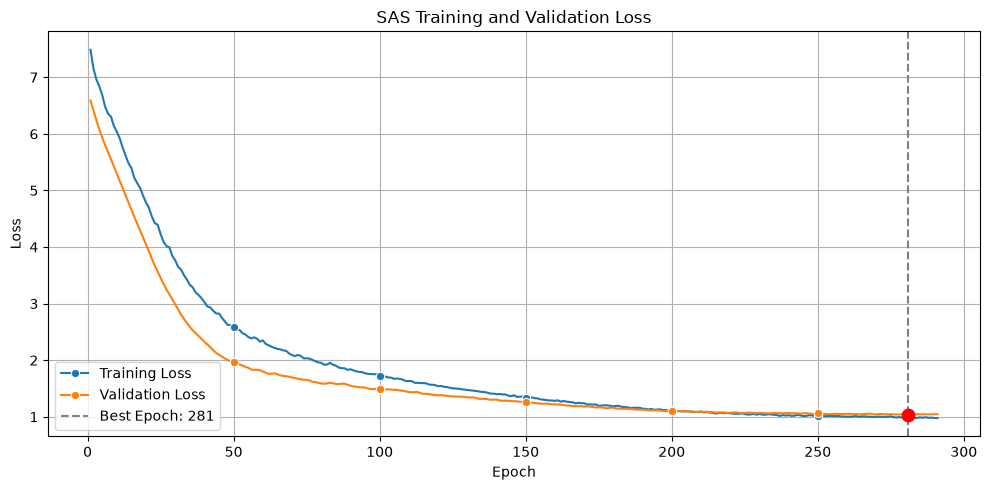

In [10]:
plotTrainingAndValidationLoss(sasData, 'SAS')

In [11]:
userId = 0

history = histories[userId]

sequence = history[:-1]
target = history[-1]

predictions = predictNextMovies(sas, sequence, topK=10)

print(f'Actual next movie: {target}')
print(f'Predicted next movie: {predictions.iloc[0]["movieId"]}')

predictions

Actual next movie: 101
Predicted next movie: 173.0


,movieId,score,probability
0,173,2.364794,0.914103
1,49,2.339622,0.912106
2,257,2.052281,0.886178
3,99,2.039264,0.884858
4,293,1.936599,0.873978
5,172,1.935337,0.873839
6,0,1.894394,0.869256
7,78,1.867078,0.866120
8,203,1.790727,0.857016
9,180,1.786449,0.856491
